In [3]:
# Modul 3 — Bayes: Jantung AI Modern

print("Nama: Agiel Munawar")
print("NPM: 2410010539")
print("Kelas: 4N Regular Pagi")

Nama: Agiel Munawar
NPM: 2410010539
Kelas: 4N Regular Pagi


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Environment siap digunakan")

Environment siap digunakan


In [5]:
P_A_dan_B = 0.30
P_B = 0.60

P_A_given_B = P_A_dan_B / P_B

print("P(A|B) =", P_A_given_B)

P(A|B) = 0.5


In [6]:
P_B_given_A = 0.90
P_A = 0.01
P_B = 0.0585

P_A_given_B = (P_B_given_A * P_A) / P_B

print("P(A|B) =", P_A_given_B)
print("Persentase =", P_A_given_B * 100, "%")

P(A|B) = 0.15384615384615385
Persentase = 15.384615384615385 %


In [7]:
P_spam = 0.20
P_normal = 0.80

P_gratis_given_spam = 0.80
P_gratis_given_normal = 0.10

P_gratis = (
    P_gratis_given_spam * P_spam
    + P_gratis_given_normal * P_normal
)

P_spam_given_gratis = (
    P_gratis_given_spam * P_spam
) / P_gratis

print("P(Gratis) =", P_gratis)
print("P(Spam|Gratis) =", P_spam_given_gratis)
print("Persentase =", P_spam_given_gratis * 100, "%")

P(Gratis) = 0.24000000000000005
P(Spam|Gratis) = 0.6666666666666666
Persentase = 66.66666666666666 %


In [8]:
P_sakit = 0.01
P_sehat = 0.99

P_positif_given_sakit = 0.99
P_positif_given_sehat = 0.01

P_positif = (
    P_positif_given_sakit * P_sakit
    + P_positif_given_sehat * P_sehat
)

P_sakit_given_positif = (
    P_positif_given_sakit * P_sakit
) / P_positif

print("P(+) =", P_positif)
print("P(Sakit|+) =", P_sakit_given_positif)
print("Persentase =", P_sakit_given_positif * 100, "%")

P(+) = 0.0198
P(Sakit|+) = 0.5
Persentase = 50.0 %


In [16]:
import pandas as pd

df = pd.read_csv(
    "/content/IMDB Dataset.csv",
    encoding="utf-8",
    engine="python"
)

print("Jumlah data:", len(df))
print("Kolom:", df.columns.tolist())

df.head()

Jumlah data: 50000
Kolom: ['review', 'sentiment']


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [17]:
# Melihat informasi dataset
df.info()

# Melihat jumlah masing-masing sentiment
print("\nJumlah masing-masing sentiment:")
print(df["sentiment"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Jumlah masing-masing sentiment:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


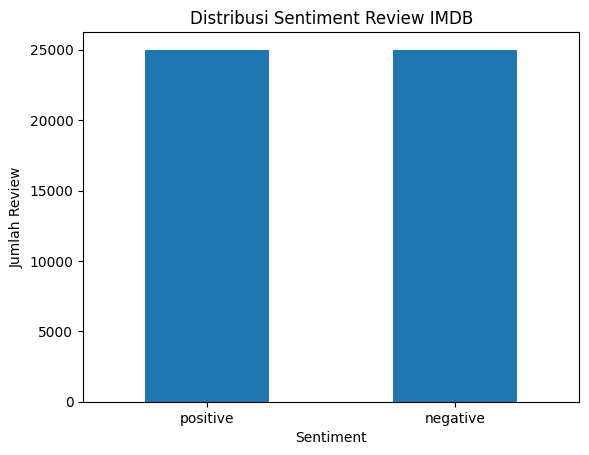

In [18]:
import matplotlib.pyplot as plt

# Menghitung jumlah sentiment
sentiment_count = df["sentiment"].value_counts()

# Membuat grafik
sentiment_count.plot(kind="bar")

plt.title("Distribusi Sentiment Review IMDB")
plt.xlabel("Sentiment")
plt.ylabel("Jumlah Review")
plt.xticks(rotation=0)
plt.show()

In [19]:
# Mencari review yang mengandung kata "great"
great_reviews = df[df["review"].str.contains("great", case=False, na=False)]

# Menghitung probabilitas positive jika review mengandung "great"
p_positive_given_great = (
    great_reviews["sentiment"] == "positive"
).mean()

print("Jumlah review yang mengandung 'great':", len(great_reviews))
print("Jumlah review positive:", (great_reviews["sentiment"] == "positive").sum())
print("P(positive | 'great') =", p_positive_given_great)
print("Dalam persen =", p_positive_given_great * 100, "%")

Jumlah review yang mengandung 'great': 13807
Jumlah review positive: 9281
P(positive | 'great') = 0.6721952632722532
Dalam persen = 67.21952632722532 %


In [20]:
# Data sederhana untuk spam filter
spam = {
    "offer": 8,
    "free": 7,
    "win": 6
}

ham = {
    "offer": 2,
    "free": 3,
    "win": 1
}

# Total jumlah kata
total_spam = sum(spam.values())
total_ham = sum(ham.values())

# Probabilitas prior
p_spam = 0.5
p_ham = 0.5

# Kata yang ingin diuji
word = "free"

# Probabilitas kata muncul pada masing-masing kelas
p_word_given_spam = spam[word] / total_spam
p_word_given_ham = ham[word] / total_ham

# Teorema Bayes
p_spam_given_word = (
    p_word_given_spam * p_spam
) / (
    p_word_given_spam * p_spam +
    p_word_given_ham * p_ham
)

print("P(free | spam) =", p_word_given_spam)
print("P(free | ham) =", p_word_given_ham)
print("P(spam | free) =", p_spam_given_word)
print("Dalam persen =", p_spam_given_word * 100, "%")

P(free | spam) = 0.3333333333333333
P(free | ham) = 0.5
P(spam | free) = 0.4
Dalam persen = 40.0 %


In [21]:
# Data diagnosis medis sederhana

p_covid = 0.01          # 1% populasi terkena COVID
p_test_positive = 0.05  # 5% hasil tes positif

# Misalkan:
# P(positif | COVID) = 0.95
# P(positif | tidak COVID) = 0.04

p_positive_given_covid = 0.95
p_positive_given_not_covid = 0.04

p_not_covid = 1 - p_covid

# Teorema Bayes
p_covid_given_positive = (
    p_positive_given_covid * p_covid
) / (
    p_positive_given_covid * p_covid +
    p_positive_given_not_covid * p_not_covid
)

print("P(COVID | hasil tes positif) =", p_covid_given_positive)
print("Dalam persen =", p_covid_given_positive * 100, "%")

P(COVID | hasil tes positif) = 0.19348268839103866
Dalam persen = 19.348268839103866 %


In [22]:
import re

def clean_text(text):
    # Ubah menjadi huruf kecil
    text = text.lower()

    # Hapus tag HTML
    text = re.sub(r"<.*?>", " ", text)

    # Hapus karakter selain huruf dan spasi
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Hapus spasi berlebihan
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Membuat kolom review yang sudah dibersihkan
df["clean_review"] = df["review"].apply(clean_text)

# Melihat hasil sebelum dan sesudah cleaning
print("SEBELUM:")
print(df["review"].iloc[0])

print("\nSESUDAH:")
print(df["clean_review"].iloc[0])

SEBELUM:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due t

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Data input dan target
X = df["clean_review"]
y = df["sentiment"]

# Membagi data menjadi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 40000
Jumlah data testing: 10000


In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Membuat TF-IDF Vectorizer
vectorizer = TfidfVectorizer()

# Belajar dari data training
X_train_vec = vectorizer.fit_transform(X_train)

# Mengubah data testing menggunakan vocabulary yang sama
X_test_vec = vectorizer.transform(X_test)

print("Ukuran data training:", X_train_vec.shape)
print("Ukuran data testing:", X_test_vec.shape)

Ukuran data training: (40000, 90489)
Ukuran data testing: (10000, 90489)


In [25]:
from sklearn.naive_bayes import MultinomialNB

# Membuat model
model = MultinomialNB()

# Training model
model.fit(X_train_vec, y_train)

print("Model Multinomial Naive Bayes berhasil dilatih.")

Model Multinomial Naive Bayes berhasil dilatih.


In [26]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Melakukan prediksi
y_pred = model.predict(X_test_vec)

# Menghitung akurasi
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100, "%")

Accuracy: 0.8665
Accuracy (%): 86.65 %


In [27]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

    negative       0.85      0.89      0.87      5000
    positive       0.88      0.84      0.86      5000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000

Confusion Matrix:
[[4444  556]
 [ 779 4221]]


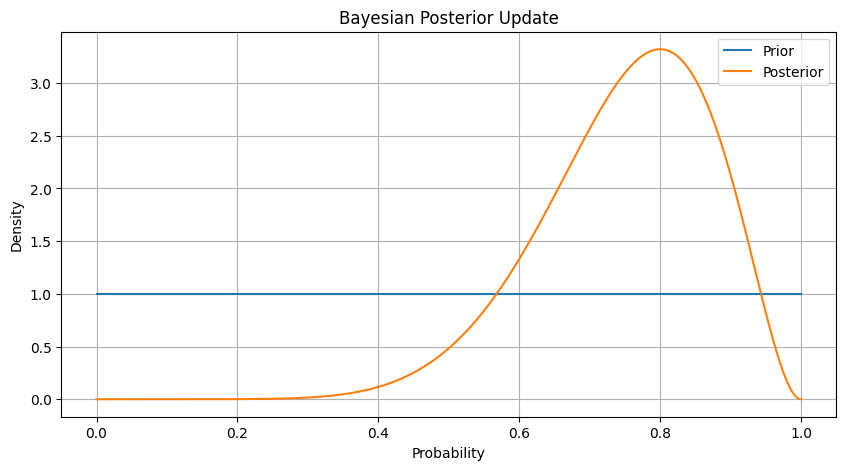

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# Prior awal
alpha_prior = 1
beta_prior = 1

# Contoh data observasi
success = 8
failure = 2

# Posterior
alpha_post = alpha_prior + success
beta_post = beta_prior + failure

# Nilai x
x = np.linspace(0, 1, 1000)

# Distribusi prior dan posterior
prior = beta.pdf(x, alpha_prior, beta_prior)
posterior = beta.pdf(x, alpha_post, beta_post)

# Visualisasi
plt.figure(figsize=(10, 5))

plt.plot(x, prior, label="Prior")
plt.plot(x, posterior, label="Posterior")

plt.xlabel("Probability")
plt.ylabel("Density")
plt.title("Bayesian Posterior Update")

plt.legend()
plt.grid()
plt.show()

In [29]:
# Review baru yang ingin diprediksi
new_review = [
    "This movie was amazing, the story was great and the acting was excellent"
]

# Membersihkan review
new_review_clean = [clean_text(review) for review in new_review]

# Mengubah review menjadi TF-IDF
new_review_vec = vectorizer.transform(new_review_clean)

# Melakukan prediksi
prediction = model.predict(new_review_vec)

# Melihat probabilitas prediksi
probability = model.predict_proba(new_review_vec)

print("Review:", new_review[0])
print("Prediksi sentiment:", prediction[0])
print("Probabilitas [negative, positive]:", probability[0])

Review: This movie was amazing, the story was great and the acting was excellent
Prediksi sentiment: positive
Probabilitas [negative, positive]: [0.2064364 0.7935636]


In [30]:
# Dua review baru untuk diuji
new_reviews = [
    "This movie was amazing, the story was great and the acting was excellent",
    "This movie was terrible, boring and a complete waste of time"
]

# Cleaning
new_reviews_clean = [clean_text(review) for review in new_reviews]

# TF-IDF
new_reviews_vec = vectorizer.transform(new_reviews_clean)

# Prediksi
predictions = model.predict(new_reviews_vec)

# Probabilitas
probabilities = model.predict_proba(new_reviews_vec)

# Tampilkan hasil
for i in range(len(new_reviews)):
    print("Review:", new_reviews[i])
    print("Prediksi:", predictions[i])
    print("Probabilitas [negative, positive]:", probabilities[i])
    print("-" * 80)

Review: This movie was amazing, the story was great and the acting was excellent
Prediksi: positive
Probabilitas [negative, positive]: [0.2064364 0.7935636]
--------------------------------------------------------------------------------
Review: This movie was terrible, boring and a complete waste of time
Prediksi: negative
Probabilitas [negative, positive]: [0.96677866 0.03322134]
--------------------------------------------------------------------------------


## 10. REFLEKSI

#### Jawaban Refleksi

**1. Apa yang dipelajari dari probabilitas bersyarat?**

Probabilitas bersyarat digunakan untuk mengetahui peluang suatu kejadian berdasarkan adanya kondisi atau informasi tertentu. Pada dataset IMDB, diperoleh nilai P(positive | mengandung "great") sebesar 67,22%.

**2. Bagaimana penerapan Teorema Bayes pada praktikum ini?**

Teorema Bayes digunakan untuk memperbarui probabilitas berdasarkan bukti yang diperoleh. Pada simulasi spam filter, diperoleh P(spam | "free") sebesar 40%, sedangkan pada simulasi diagnosis medis diperoleh P(COVID | hasil tes positif) sebesar 19,35%.

**3. Bagaimana proses klasifikasi sentiment menggunakan Naive Bayes?**

Review dibersihkan terlebih dahulu melalui proses text preprocessing, kemudian diubah menjadi representasi angka menggunakan TF-IDF. Data tersebut digunakan untuk melatih algoritma Multinomial Naive Bayes dalam mengklasifikasikan review menjadi sentiment positive atau negative.

**4. Bagaimana hasil pengujian model?**

Model Multinomial Naive Bayes menghasilkan accuracy sebesar 87% pada 10.000 data testing. Hasil tersebut memenuhi target akurasi lebih dari 85%. Confusion matrix menunjukkan 4.444 data negative dan 4.221 data positive berhasil diklasifikasikan dengan benar.

**5. Apa kesimpulan dari praktikum Modul 3?**

Praktikum ini menunjukkan bahwa konsep probabilitas bersyarat dan Teorema Bayes dapat diterapkan dalam machine learning, khususnya untuk klasifikasi sentiment. Penggunaan TF-IDF dan Multinomial Naive Bayes mampu menghasilkan model dengan accuracy 87% pada dataset IMDB.